# Avance 3. Baseline

**Proyecto Integrador (TC5035.10) · Equipo 48 · Planograma: IA para detección de productos y ubicación**

| Integrante | Matrícula |
|---|---|
| Oscar Alberto Ramírez Anaya | A01795438 |
| Germán Eduardo Rodríguez Vázquez | A01796325 |
| Jesús Soto Medrano | A01794746 |

Profesora: Dra. Grettel Barceló Alonso · Asesor: Dr. Raúl Valente Ramírez · Patrocinador: Dr. Juan Arturo Nolazco Flores · Organización: Bnext

---

**Fase CRISP-ML(Q):** Ingeniería del modelo (*Model Engineering*). Este avance construye un modelo de
referencia (*baseline*) para el reconocimiento de producto en recortes de anaquel, con dos objetivos:
establecer las medidas de calidad del modelo y fijar un marco de comparación para los modelos más
avanzados de los siguientes avances. Las preguntas que guían la libreta son:

1. ¿Qué algoritmo sirve como baseline para predecir la variable objetivo? (secciones 4 y 5)
2. ¿Qué características son importantes para el modelo? (sección 6)
3. ¿El modelo sub o sobreajusta los datos de entrenamiento? (sección 7)
4. ¿Cuál es la métrica adecuada para el problema de negocio? (sección 8)
5. ¿Cuál debería ser el desempeño mínimo a obtener? (sección 9)

**Manejo de datos.** Conforme al acuerdo con Bnext (`POLITICA_DATOS.md`), la libreta se ejecuta
dentro del servidor de la organización. Las imágenes no salen de esa infraestructura y la libreta
publicada contiene únicamente tablas y gráficas agregadas: no se muestran fotografías ni recortes, y
las clases se anonimizan como `SKU_###` (carpetas con código de producto) y `GRP_###` (carpetas de
agrupamiento).

## 0. Configuración

Las rutas se leen de variables de entorno (`PLANOGRAMA_DATA_DIR` para los datos y
`PLANOGRAMA_OUT_DIR` para las salidas tabulares y el modelo ajustado), de modo que el código no
contiene ubicaciones del servidor. La semilla `SEED = 48` fija todo componente estocástico y
`PLANOGRAMA_N_JOBS` limita los núcleos usados, porque el servidor es compartido.

In [1]:
import os, re, time, warnings, pathlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from skimage.feature import hog, local_binary_pattern
from skimage.measure import shannon_entropy
from joblib import Parallel, delayed
import joblib

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, LabelEncoder
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, learning_curve, validation_curve
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, top_k_accuracy_score,
                             log_loss, precision_recall_fscore_support, confusion_matrix)
from sklearn.exceptions import ConvergenceWarning

SEED = 48
np.random.seed(SEED)
N_JOBS = int(os.environ.get('PLANOGRAMA_N_JOBS', 6))
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message='.*constant.*', category=UserWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
# En los tamaños pequeños de la curva de aprendizaje hay pocas muestras por clase; es esperado
warnings.filterwarnings('ignore', message='.*number of unique classes.*')
os.environ['PYTHONWARNINGS'] = 'ignore'  # se hereda a los procesos paralelos de joblib

DATA_DIR = pathlib.Path(os.environ.get('PLANOGRAMA_DATA_DIR', 'data/raw'))
OUT_DIR = pathlib.Path(os.environ.get('PLANOGRAMA_OUT_DIR', 'outputs'))
OUT_DIR.mkdir(parents=True, exist_ok=True)
SKU_DIR = DATA_DIR / 'skus' / 'images'
if not SKU_DIR.exists():
    SKU_DIR = DATA_DIR / 'skus'
assert SKU_DIR.exists(), 'Definir PLANOGRAMA_DATA_DIR con la ubicación de los datos'

print('numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| OpenCV', cv2.__version__, '| núcleos', N_JOBS)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | OpenCV 5.0.0 | núcleos 6


## 1. Problema y datos

**Variable objetivo.** El planograma exige saber *qué producto* ocupa cada posición del anaquel: un
producto correcto, uno faltante o uno mal ubicado se decide comparando el producto reconocido contra
el prescrito. La tarea que se modela en este avance es por ello la **clasificación multiclase de
recortes de producto**: dado el recorte de un producto, predecir su clase.

**Por qué no un detector todavía.** El plan inicial contemplaba como línea base un detector
preentrenado sobre las escenas completas. La revisión de los datos disponibles en el servidor de
Bnext muestra que las escenas de refrigeradores y vitrinas no tienen anotaciones (cajas delimitadoras
ni planogramas de referencia), por lo que un detector no puede evaluarse con métricas; además el
servidor no cuenta con GPU. Los recortes, en cambio, sí tienen una etiqueta por carpeta y permiten
medir el componente de reconocimiento, que es el que distingue entre “correcto” y “mal ubicado”.

**Datos.** Bnext entregó, además de la muestra usada en el Avance 2, un conjunto ampliado de recortes
organizado en carpetas. Hay dos tipos de carpeta:

- **Con código de producto** (`SKU_###`): la carpeta lleva el código del artículo. Son los mismos 35
  productos del Avance 2.
- **De agrupamiento** (`GRP_###`): carpetas nombradas `cluster_NNN`. No se dispone de una tabla que
  asocie cada agrupamiento con un producto, por lo que **se asume que cada carpeta corresponde a un
  producto distinto**. Este supuesto está pendiente de validar con Bnext y se revisa en la sección 8
  comparando el desempeño por tipo de carpeta.

Se usan ambos tipos para tener el mayor volumen posible de clases e imágenes.

In [2]:
EXT = {'.jpg', '.jpeg', '.png'}
carpetas = sorted(d for d in SKU_DIR.iterdir() if d.is_dir())
con_codigo = [d for d in carpetas if not d.name.startswith('cluster_')]
agrupadas = [d for d in carpetas if d.name.startswith('cluster_')]
anonimo = {d.name: f'SKU_{i:03d}' for i, d in enumerate(con_codigo, start=1)}
anonimo.update({d.name: f'GRP_{i:03d}' for i, d in enumerate(agrupadas, start=1)})
origen_de = {d.name: ('código' if d in con_codigo else 'agrupamiento') for d in carpetas}

# El nombre de archivo solo se usa para ordenar las capturas en el tiempo; nunca se imprime
recortes = [(anonimo[d.name], origen_de[d.name], p) for d in carpetas
            for p in sorted(d.iterdir(), key=lambda q: q.name.lower()) if p.suffix.lower() in EXT]

def mes_captura(nombre):
    m = re.search(r'(20\d{2})(\d{2})\d{2}_?\d{6}', nombre)
    return f'{m.group(1)}-{m.group(2)}' if m else 'sin fecha en nombre'

inv = pd.DataFrame({'clase': [c for c, _, _ in recortes], 'origen': [o for _, o, _ in recortes],
                    'mes': [mes_captura(p.name) for _, _, p in recortes]})
por_clase = inv.groupby(['origen', 'clase']).size().rename('imágenes').reset_index()
resumen = por_clase.groupby('origen')['imágenes'].agg(clases='size', imágenes='sum', mínimo='min',
                                                    mediana='median', máximo='max')
resumen.loc['total'] = [por_clase['clase'].nunique(), len(inv), por_clase['imágenes'].min(),
                        por_clase['imágenes'].median(), por_clase['imágenes'].max()]
display(resumen)
display(pd.crosstab(inv['mes'], inv['origen'], margins=True, margins_name='total'))
print(f'Razón de desbalance (máx/mín imágenes por clase): '
      f'{por_clase["imágenes"].max() / por_clase["imágenes"].min():.1f}x')

,clases,imágenes,mínimo,mediana,máximo
origen,,,,,
agrupamiento,206.0,2465.0,5.0,11.0,32.0
código,35.0,422.0,10.0,11.0,24.0
total,241.0,2887.0,5.0,11.0,32.0


origen,agrupamiento,código,total
mes,,,
2026-01,0,339,339
2026-06,2284,0,2284
sin fecha en nombre,181,83,264
total,2465,422,2887


Razón de desbalance (máx/mín imágenes por clase): 6.4x


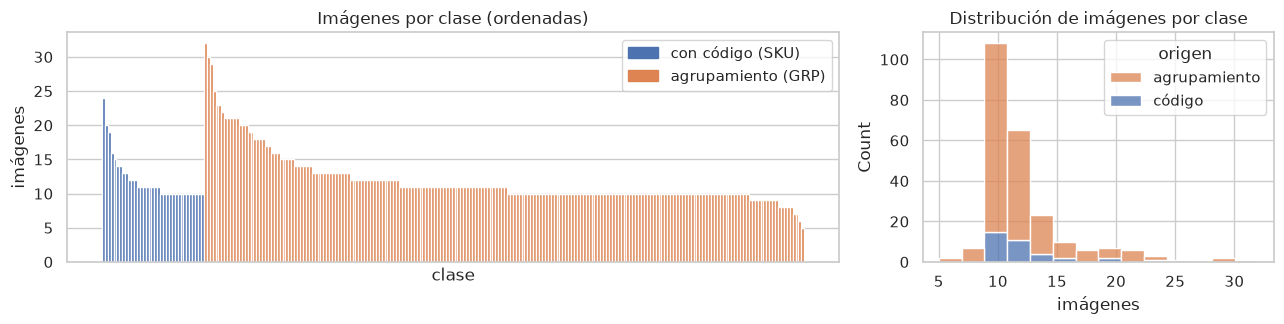

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={'width_ratios': [2.2, 1]})
orden = por_clase.sort_values(['origen', 'imágenes'], ascending=[False, False])
colores = orden['origen'].map({'código': '#4C72B0', 'agrupamiento': '#DD8452'})
axes[0].bar(range(len(orden)), orden['imágenes'], color=colores, width=1.0)
axes[0].set(title='Imágenes por clase (ordenadas)', xlabel='clase', ylabel='imágenes', xticks=[])
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#4C72B0'),
                        plt.Rectangle((0, 0), 1, 1, color='#DD8452')],
               labels=['con código (SKU)', 'agrupamiento (GRP)'])
sns.histplot(data=por_clase, x='imágenes', hue='origen', multiple='stack', binwidth=2, ax=axes[1],
             palette={'código': '#4C72B0', 'agrupamiento': '#DD8452'})
axes[1].set(title='Distribución de imágenes por clase')
plt.tight_layout(); plt.show()

**Interpretación.** El conjunto de trabajo tiene **2 887 recortes de 241 clases**: 35 con código de
producto (422 recortes, los mismos del Avance 2) y 206 carpetas de agrupamiento (2 465 recortes). Es
casi siete veces más imágenes y más de seis veces más clases que en el Avance 2, lo que hace el problema
bastante más difícil: el azar uniforme pasa de 1/35 a 1/241. La mediana es de 11 imágenes por clase y el
desbalance sube a 6.4 veces (de 5 a 32 imágenes), pero ninguna clase domina el conjunto, así que no se
remuestrea; el desbalance se atiende con la elección de la métrica (sección 8).

Las fechas en los nombres de archivo muestran que **cada tipo de carpeta proviene de una campaña de
captura distinta** (enero de 2026 para las carpetas con código y junio de 2026 para las de agrupamiento)
y que, dentro de cada clase, las fotos son de una sola sesión. Esto tiene dos consecuencias: las
variables de captura (resolución, tamaño de archivo) pueden diferir entre los dos tipos de carpeta sin
que eso tenga relación con el producto, y las métricas de este avance miden la separabilidad entre
productos fotografiados en una misma sesión, no la generalización a otra tienda o a otro día.

## 2. Extracción de características

Se reutiliza la extracción definida y justificada en el Avance 2, ahora sobre todas las imágenes. Cada
recorte se convierte en un vector de características agrupadas en familias:

| Familia | Contenido |
|---|---|
| Geometría y archivo | ancho, alto, área, relación de aspecto, tamaño en KB |
| Exposición y calidad | brillo, contraste, nitidez (varianza del Laplaciano), densidad de bordes, entropía, fracción sub y sobreexpuesta |
| Color global | saturación, *colorfulness*, fracción de blanco, matiz circular (`hue_x`, `hue_y`), momentos de color en Lab |
| Histogramas HSV | 12 intervalos de matiz, 4 de saturación y 4 de valor |
| Textura LBP | histograma de patrones binarios locales uniformes |
| Forma HOG | histograma de gradientes orientados sobre el recorte normalizado a 64×128 |
| Construidas | megapíxeles, KB por megapíxel, nitidez por borde, exposición, índice de calidad, banderas de calidad y discretizaciones de iluminación y formato de empaque |

Como en el Avance 2, la fuente de captura derivada del nombre de archivo se excluye por ser fuga de
información.

In [4]:
HOG_TAM = (64, 128)
H_BINS, S_BINS, V_BINS = 12, 4, 4

def colorfulness(bgr):
    b, g, r = [c.astype(float) for c in cv2.split(bgr)]
    rg, yb = r - g, 0.5 * (r + g) - b
    return np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())

def rasgos_recorte(ruta):
    bgr = cv2.imread(str(ruta))
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = [hsv[..., i].astype(float) for i in range(3)]
    alto, ancho = gray.shape
    ang = np.deg2rad(h * 2.0); w = s / 255.0 + 1e-9
    f = {'ancho': ancho, 'alto': alto, 'area_px': ancho * alto, 'aspecto': alto / ancho,
         'archivo_kb': ruta.stat().st_size / 1024,
         'brillo': v.mean(), 'contraste': gray.std(),
         'nitidez': cv2.Laplacian(gray, cv2.CV_64F).var(),
         'densidad_bordes': (cv2.Canny(gray, 100, 200) > 0).mean(),
         'entropia': shannon_entropy(gray),
         'frac_subexp': (v < 15).mean(), 'frac_sobreexp': (v > 245).mean(),
         'saturacion': s.mean(), 'colorfulness': colorfulness(bgr),
         'frac_blanco': ((s < 30) & (v > 200)).mean(),
         'hue_x': np.average(np.cos(ang), weights=w), 'hue_y': np.average(np.sin(ang), weights=w)}
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(float)
    for i, canal in enumerate('Lab'):
        f[f'{canal}_media'] = lab[:, i].mean(); f[f'{canal}_desv'] = lab[:, i].std()
        f[f'{canal}_sesgo'] = stats.skew(lab[:, i])
    sat = hsv[..., 1] > 40
    hh = np.histogram(hsv[..., 0][sat], bins=H_BINS, range=(0, 180))[0]
    f.update({f'hist_h{i:02d}': x / max(hh.sum(), 1) for i, x in enumerate(hh)})
    for canal, n in ((1, S_BINS), (2, V_BINS)):
        hc = np.histogram(hsv[..., canal], bins=n, range=(0, 256))[0] / hsv[..., canal].size
        f.update({f'hist_{"sv"[canal - 1]}{i}': x for i, x in enumerate(hc)})
    g128 = cv2.resize(gray, (128, 128), interpolation=cv2.INTER_AREA)
    lbp = local_binary_pattern(g128, P=8, R=1, method='uniform')
    hl = np.histogram(lbp, bins=10, range=(0, 10))[0] / lbp.size
    f.update({f'lbp_{i}': x for i, x in enumerate(hl)})
    ghog = cv2.resize(gray, HOG_TAM, interpolation=cv2.INTER_AREA)
    vec = hog(ghog, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
              block_norm='L2-Hys')
    f.update({f'hog_{i:03d}': x for i, x in enumerate(vec)})
    return f

def extraer(item):
    clase, origen, ruta = item
    try:
        return {'clase': clase, 'origen': origen, **rasgos_recorte(ruta)}
    except Exception as e:  # imagen ilegible o corrupta
        return {'clase': clase, 'origen': origen, 'error': type(e).__name__}

t0 = time.time()
df = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(extraer)(r) for r in recortes))
if 'error' in df:
    print('Imágenes no legibles descartadas:', int(df['error'].notna().sum()))
    df = df[df['error'].isna()].drop(columns='error').reset_index(drop=True)
print(f'Extracción en {time.time() - t0:.0f} s | recortes {df.shape[0]} | columnas {df.shape[1] - 2}')

Extracción en 79 s | recortes 2887 | columnas 812


In [5]:
def construir(d):
    d = d.copy()
    d['megapixeles'] = d['area_px'] / 1e6
    d['kb_por_mp'] = d['archivo_kb'] / d['megapixeles']
    d['nitidez_por_borde'] = d['nitidez'] / (d['densidad_bordes'] + 1e-3)
    d['exposicion_ok'] = 1 - (d['brillo'] - 128).abs() / 128
    d['indice_calidad'] = (d['exposicion_ok']
                           + np.minimum(1, np.log1p(d['nitidez']) / np.log(501))
                           + np.minimum(1, d['contraste'] / 64)) / 3
    d['flag_borrosa'] = (d['nitidez'] < 100).astype(int)
    d['flag_oscura'] = (d['brillo'] < 60).astype(int)
    d['flag_sobreexpuesta'] = (d['frac_sobreexp'] > 0.10).astype(int)
    d['nivel_iluminacion_ord'] = pd.cut(d['brillo'], [-np.inf, 60, 190, np.inf], labels=False)
    d['formato_empaque_ord'] = pd.cut(d['aspecto'], [-np.inf, 0.8, 1.25, 2.0, np.inf], labels=False)
    return d

df = construir(df)
FAMILIAS = {
    'geometría y archivo': ['ancho', 'alto', 'area_px', 'aspecto', 'archivo_kb'],
    'exposición y calidad': ['brillo', 'contraste', 'nitidez', 'densidad_bordes', 'entropia',
                             'frac_subexp', 'frac_sobreexp'],
    'color global': ['saturacion', 'colorfulness', 'frac_blanco', 'hue_x', 'hue_y']
                    + [c for c in df if c[:2] in ('L_', 'a_', 'b_')],
    'histogramas HSV': [c for c in df if c.startswith('hist_')],
    'textura LBP': [c for c in df if c.startswith('lbp_')],
    'forma HOG': [c for c in df if c.startswith('hog_')],
    'construidas': ['megapixeles', 'kb_por_mp', 'nitidez_por_borde', 'exposicion_ok', 'indice_calidad',
                    'flag_borrosa', 'flag_oscura', 'flag_sobreexpuesta', 'nivel_iluminacion_ord',
                    'formato_empaque_ord'],
}
FAMILIA_DE = {c: f for f, cols in FAMILIAS.items() for c in cols}
FEATS = [c for cols in FAMILIAS.values() for c in cols]
display(pd.Series({k: len(v) for k, v in FAMILIAS.items()}, name='variables').to_frame().T)
print('Características totales:', len(FEATS), '| faltantes:', int(df[FEATS].isna().sum().sum()))

,geometría y archivo,exposición y calidad,color global,histogramas HSV,textura LBP,forma HOG,construidas
variables,5,7,14,20,10,756,10


Características totales: 822 | faltantes: 0


## 3. Partición sin fuga y preparación

Se conserva el esquema del Avance 2. Las fotos de cada clase se tomaron en ráfagas, de modo que dos
recortes consecutivos son casi duplicados; una partición aleatoria pondría fotos gemelas en
entrenamiento y prueba e inflaría las métricas. Por eso:

- **Prueba:** el 30 % final de las capturas de cada clase, en orden cronológico (por nombre de
  archivo). Todas las clases aparecen en ambos conjuntos y la prueba simula fotos posteriores.
- **Validación cruzada:** dentro de entrenamiento, cada clase se divide en tres bloques consecutivos y
  se usa `StratifiedGroupKFold(3)` con el bloque como grupo.

La preparación se ajusta solo con entrenamiento: transformación Box-Cox o Yeo-Johnson a las variables
con |asimetría| > 1, estandarización, eliminación de variables de varianza casi nula (< 0.001 tras
escalar a [0, 1]) y de variables redundantes (|ρ de Spearman| > 0.95). La selección final de
características se hace con ANOVA F (`SelectKBest`) dentro del pipeline, como en la configuración
elegida en el Avance 2.

In [6]:
le = LabelEncoder().fit(df['clase'])
y = le.transform(df['clase'])
ETIQUETAS = np.arange(len(le.classes_))
ORIGEN_CLASE = df.groupby('clase')['origen'].first().reindex(le.classes_).to_numpy()

df['orden'] = df.groupby('clase').cumcount()
df['pos_rel'] = df['orden'] / df.groupby('clase')['clase'].transform('size')
es_train = (df['pos_rel'] < 0.7).to_numpy()
bloque = np.minimum((df['pos_rel'] / 0.7 * 3).astype(int), 2)
grupos = (df['clase'] + '_b' + bloque.astype(str)).to_numpy()

X = df[FEATS].astype(float)
X_tr, X_te, y_tr, y_te = X[es_train], X[~es_train], y[es_train], y[~es_train]
g_tr = grupos[es_train]
CV = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
print(f'Entrenamiento: {es_train.sum()} | Prueba: {(~es_train).sum()} | '
      f'clases en prueba: {len(np.unique(y_te))}/{len(ETIQUETAS)}')

# Transformaciones de potencia (diagnóstico solo con entrenamiento)
CONTINUAS = [c for c in FEATS if not c.startswith(('hist_', 'hog_', 'lbp_', 'flag_'))
             and not c.endswith('_ord')]
sesgo = X_tr[CONTINUAS].skew()
ASIM = sesgo[sesgo.abs() > 1].index.tolist()
BOXCOX = [c for c in ASIM if (X[c] > 0).all()]
YEOJ = [c for c in ASIM if c not in BOXCOX]

# Filtros de varianza y redundancia
vt = VarianceThreshold(1e-3).fit(MinMaxScaler().fit_transform(X_tr))
tras_var = [c for c, k in zip(FEATS, vt.get_support()) if k]
rho = X_tr[tras_var].corr(method='spearman').abs()
triang = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
redundantes = [c for c in triang.columns if (triang[c] > 0.95).any()]
cand = [c for c in tras_var if c not in redundantes]
print(f'Asimétricas: {len(ASIM)} (Box-Cox {len(BOXCOX)}, Yeo-Johnson {len(YEOJ)}) | '
      f'varianza casi nula: {len(FEATS) - len(tras_var)} | redundantes: {len(redundantes)} | '
      f'candidatas: {len(cand)}')

Entrenamiento: 2088 | Prueba: 799 | clases en prueba: 241/241


Asimétricas: 13 (Box-Cox 10, Yeo-Johnson 3) | varianza casi nula: 1 | redundantes: 205 | candidatas: 616


In [7]:
def preparacion(cols):
    return [('potencia', ColumnTransformer(
                [('boxcox', PowerTransformer('box-cox', standardize=False), [c for c in BOXCOX if c in cols]),
                 ('yeoj', PowerTransformer('yeo-johnson', standardize=False), [c for c in YEOJ if c in cols])],
                remainder='passthrough', verbose_feature_names_out=False)),
            ('escala', StandardScaler())]

def pipe(clf, k=None, cols=None):
    cols = cols or cand
    pasos = preparacion(cols)
    if k is not None and k < len(cols):
        pasos.append(('seleccion', SelectKBest(f_classif, k=k)))
    return Pipeline(pasos + [('clf', clf)])

def probas(m, Xd):
    P = np.zeros((len(Xd), len(ETIQUETAS)))
    P[:, m.classes_] = m.predict_proba(Xd)
    P = np.clip(P, 1e-15, 1)
    return P / P.sum(axis=1, keepdims=True)

def metricas(m, Xd, yd):
    pred = m.predict(Xd)
    r = {'F1 macro': f1_score(yd, pred, average='macro'),
         'exactitud': accuracy_score(yd, pred),
         'exactitud balanceada': balanced_accuracy_score(yd, pred)}
    if hasattr(m, 'predict_proba'):
        P = probas(m, Xd)
        r['top-3'] = top_k_accuracy_score(yd, P, k=3, labels=ETIQUETAS)
        r['log-loss'] = log_loss(yd, P, labels=ETIQUETAS)
    return r

def evaluar_cv(modelo, cols=None):
    cols = cols or cand
    filas = []
    for f_tr, f_va in CV.split(X_tr, y_tr, g_tr):
        m = clone(modelo); t0 = time.time()
        m.fit(X_tr.iloc[f_tr][cols], y_tr[f_tr])
        filas.append({**metricas(m, X_tr.iloc[f_va][cols], y_tr[f_va]), 'seg ajuste': time.time() - t0})
    return pd.DataFrame(filas)

def logistica(C=1.0):
    return LogisticRegression(C=C, max_iter=5000, random_state=SEED)

## 4. Referencia de azar

Antes de proponer un algoritmo se mide qué se obtiene **sin aprender nada** de las imágenes, con tres
clasificadores triviales (`DummyClassifier`): predecir siempre la clase más frecuente, predecir al azar
respetando las proporciones de entrenamiento y predecir al azar con probabilidad uniforme. Con más de
doscientas clases, cualquier modelo útil debe quedar muy por encima de estos valores; si el baseline
no lo hiciera, indicaría que las características no contienen información sobre el producto.

In [8]:
DUMMIES = {'más frecuente': DummyClassifier(strategy='most_frequent'),
           'estratificado': DummyClassifier(strategy='stratified', random_state=SEED),
           'uniforme': DummyClassifier(strategy='uniform', random_state=SEED)}
filas = []
for nom, d in DUMMIES.items():
    cv_d = evaluar_cv(d)
    m = clone(d).fit(X_tr[cand], y_tr)
    filas.append({'referencia': nom, 'F1 macro CV': cv_d['F1 macro'].mean(),
                  **{f'{k} prueba': v for k, v in metricas(m, X_te[cand], y_te).items()}})
azar = pd.DataFrame(filas).set_index('referencia')
display(azar.round(4))
print(f'Valor teórico de exactitud al azar uniforme: 1/{len(ETIQUETAS)} = {1 / len(ETIQUETAS):.4f}')

,F1 macro CV,F1 macro prueba,exactitud prueba,exactitud balanceada prueba,top-3 prueba,log-loss prueba
referencia,,,,,,
más frecuente,0.0001,0.0001,0.0113,0.0041,0.0188,34.1497
estratificado,0.0037,0.0034,0.0038,0.0035,0.0113,34.4091
uniforme,0.0055,0.0061,0.0088,0.0078,0.0113,5.4848


Valor teórico de exactitud al azar uniforme: 1/241 = 0.0041


## 5. Algoritmo baseline

**Elección: regresión logística multinomial** sobre las características preparadas y seleccionadas
con ANOVA. Los criterios para elegirla como referencia son:

- **Tipo de datos.** Tras la extracción, el problema es tabular: cada recorte es un vector numérico
  de longitud fija con variables continuas y estandarizadas. Un modelo lineal es el punto de partida
  natural para este tipo de entrada (Géron, 2022, cap. 4).
- **Cantidad de datos.** Hay pocas imágenes por clase (entre 5 y 32). Un modelo con pocos
  hiperparámetros y regularización L2 por defecto tiene menos riesgo de memorizar que un modelo
  flexible, y entrena en segundos en CPU.
- **Características relevantes.** La regresión logística es sensible a variables irrelevantes y a la
  escala, por eso se combina con la preparación y la selección ANOVA del Avance 2; a cambio, sus
  coeficientes sobre variables estandarizadas indican directamente qué características usa.
- **Interpretabilidad y salida probabilística.** Entrega una probabilidad por clase, útil para el
  negocio: una predicción con baja confianza puede enviarse a revisión manual en lugar de generar una
  alerta, y el top-3 permite proponer alternativas al auditor.
- **Continuidad.** Es el modelo con el que se validaron las decisiones de preparación del Avance 2,
  de modo que el baseline mide el efecto de ampliar los datos sin cambiar la receta.

Primero se ajusta el número de características `k` con validación cruzada. Después la regresión
logística se contrasta con otros algoritmos simples (kNN, Bayes ingenuo gaussiano, árbol de decisión
y bosque aleatorio) bajo la misma preparación y validación, para comprobar que la elección no deja
desempeño importante sobre la mesa.

,k,F1 CV,desv,seg ajuste
0,25,0.769,0.009,3.481
1,50,0.849,0.014,9.997
2,100,0.774,0.016,12.791
3,200,0.720,0.027,5.727
4,400,0.694,0.018,4.013
5,616,0.675,0.019,4.348


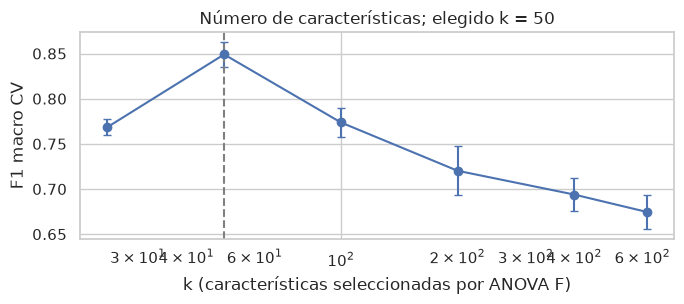

In [9]:
KS = [25, 50, 100, 200, 400, len(cand)]
curva_k = []
for k in KS:
    r = evaluar_cv(pipe(logistica(), k=k))
    curva_k.append({'k': k, 'F1 CV': r['F1 macro'].mean(), 'desv': r['F1 macro'].std(),
                    'seg ajuste': r['seg ajuste'].mean()})
curva_k = pd.DataFrame(curva_k)
K = int(curva_k.sort_values('F1 CV', ascending=False).iloc[0]['k'])
display(curva_k.round(3))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.errorbar(curva_k['k'], curva_k['F1 CV'], yerr=curva_k['desv'], marker='o', capsize=3)
ax.axvline(K, ls='--', c='gray'); ax.set_xscale('log')
ax.set(xlabel='k (características seleccionadas por ANOVA F)', ylabel='F1 macro CV',
       title=f'Número de características; elegido k = {K}')
plt.tight_layout(); plt.show()

,F1 CV,F1 CV desv,F1 prueba,exactitud prueba,top-3 prueba,seg ajuste
modelo,,,,,,
regresión logística (baseline),0.849,0.014,0.881,0.895,0.951,13.149
kNN (k=3),0.775,0.010,0.814,0.830,0.922,0.471
Bayes ingenuo gaussiano,0.685,0.013,0.817,0.827,0.874,0.504
árbol de decisión,0.513,0.016,0.606,0.628,0.628,1.373
bosque aleatorio (300),0.867,0.015,0.901,0.912,0.966,4.415


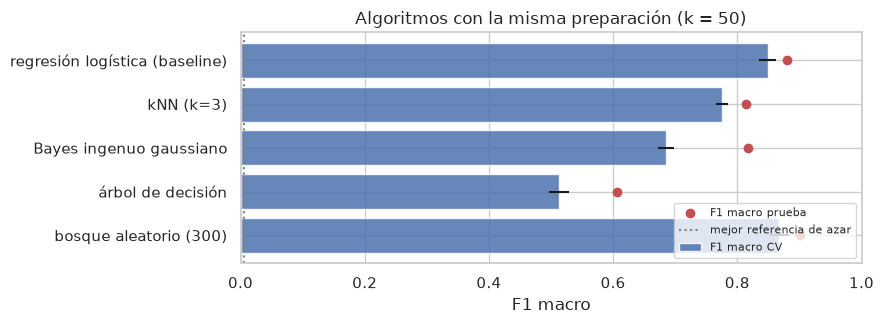

In [10]:
MODELOS = {
    'regresión logística (baseline)': logistica(),
    'kNN (k=3)': KNeighborsClassifier(n_neighbors=3),
    'Bayes ingenuo gaussiano': GaussianNB(),
    'árbol de decisión': DecisionTreeClassifier(random_state=SEED),
    'bosque aleatorio (300)': RandomForestClassifier(n_estimators=300, n_jobs=N_JOBS, random_state=SEED),
}
filas, ajustados = [], {}
for nom, clf in MODELOS.items():
    p = pipe(clf, k=K)
    r = evaluar_cv(p)
    m = clone(p); t0 = time.time(); m.fit(X_tr[cand], y_tr); dt = time.time() - t0
    ajustados[nom] = m
    te = metricas(m, X_te[cand], y_te)
    filas.append({'modelo': nom, 'F1 CV': r['F1 macro'].mean(), 'F1 CV desv': r['F1 macro'].std(),
                  'F1 prueba': te['F1 macro'], 'exactitud prueba': te['exactitud'],
                  'top-3 prueba': te.get('top-3', np.nan), 'seg ajuste': dt})
comp = pd.DataFrame(filas).set_index('modelo')
display(comp.round(3))
base = ajustados['regresión logística (baseline)']

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(comp.index[::-1], comp['F1 CV'][::-1], xerr=comp['F1 CV desv'][::-1], color='#4C72B0',
        alpha=.85, label='F1 macro CV')
ax.scatter(comp['F1 prueba'][::-1], comp.index[::-1], color='#C44E52', zorder=3, label='F1 macro prueba')
ax.axvline(azar['F1 macro prueba'].max(), color='gray', ls=':', label='mejor referencia de azar')
ax.set(xlim=(0, 1), xlabel='F1 macro', title=f'Algoritmos con la misma preparación (k = {K})')
ax.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

**Interpretación.** La curva de la selección ANOVA tiene un máximo claro en **k = 50**
(F1 macro CV 0.849 ± 0.014). Con más variables el desempeño baja de forma sostenida (0.675 con las 616
candidatas), señal de que la regresión logística se sobreajusta cuando tiene más dimensiones que
información útil por clase. Es el mismo valor de k elegido en el Avance 2, ahora con siete veces más
datos, lo que da estabilidad a la receta de preparación.

En la comparación, todos los algoritmos superan por mucho al azar (F1 ≤ 0.006). El **bosque aleatorio**
obtiene el mejor F1 (0.867 en CV y 0.901 en prueba), seguido de la **regresión logística** (0.849 y 0.881).
La diferencia en CV (0.018) es del orden de una desviación estándar entre pliegues, así que los dos
modelos quedan prácticamente empatados. kNN (0.775), Bayes ingenuo (0.685) y el árbol de decisión (0.513)
quedan claramente por debajo. El árbol individual es el más débil porque con 5 a 32 ejemplos por clase
cada hoja termina decidiendo con muy pocos recortes.

**Se mantiene la regresión logística como baseline** por tres razones. Primero, sus probabilidades
están mejor calibradas: su log-loss en prueba es 0.63, frente a 0.99 del bosque aleatorio (sección 7), y
eso importa para decidir qué predicciones mandar a revisión manual. Segundo, es interpretable a través de
sus coeficientes. Tercero, es el modelo de referencia del Avance 2, así que la comparación entre avances
es directa. El bosque aleatorio queda registrado como el primer candidato a superar el baseline en el
Avance 4, junto con los modelos de aprendizaje profundo.

## 6. Importancia de las características

Se combinan tres tipos de método para no depender de uno solo:

- **Filtro:** el estadístico F de ANOVA que usa `SelectKBest`, que mide cuánto separa cada variable a
  las clases por sí sola.
- **Embebido:** la magnitud media de los coeficientes de la regresión logística (las variables están
  estandarizadas, así que son comparables) y la importancia por impureza del bosque aleatorio.
- **Por permutación sobre prueba:** cuánto cae el F1 macro del baseline al permutar al mismo tiempo
  todas las variables de una familia. Se mide sobre prueba y por familia porque muchas variables
  están correlacionadas entre sí (por ejemplo, las celdas HOG vecinas) y permutarlas de una en una
  subestimaría su aporte.

Al final se hace una ablación: se reentrena el baseline quitando cada familia completa.

,candidatas,seleccionadas (k=50)
color global,13,13
construidas,7,1
exposición y calidad,7,6
forma HOG,554,0
geometría y archivo,5,4
histogramas HSV,20,18
textura LBP,10,8


Top 10 por ANOVA F: ['a_media', 'hist_h01', 'hist_h00', 'a_desv', 'saturacion', 'hist_h02', 'colorfulness', 'b_desv', 'hist_h11', 'hist_s0']
Top 10 por |coef| medio: ['b_sesgo', 'lbp_2', 'frac_blanco', 'hist_s1', 'hist_h00', 'hist_h01', 'contraste', 'entropia', 'ancho', 'a_sesgo']
Top 10 por impureza RF: ['b_sesgo', 'a_sesgo', 'hist_h01', 'a_desv', 'b_desv', 'hist_h00', 'frac_blanco', 'a_media', 'hist_h02', 'hist_h11']


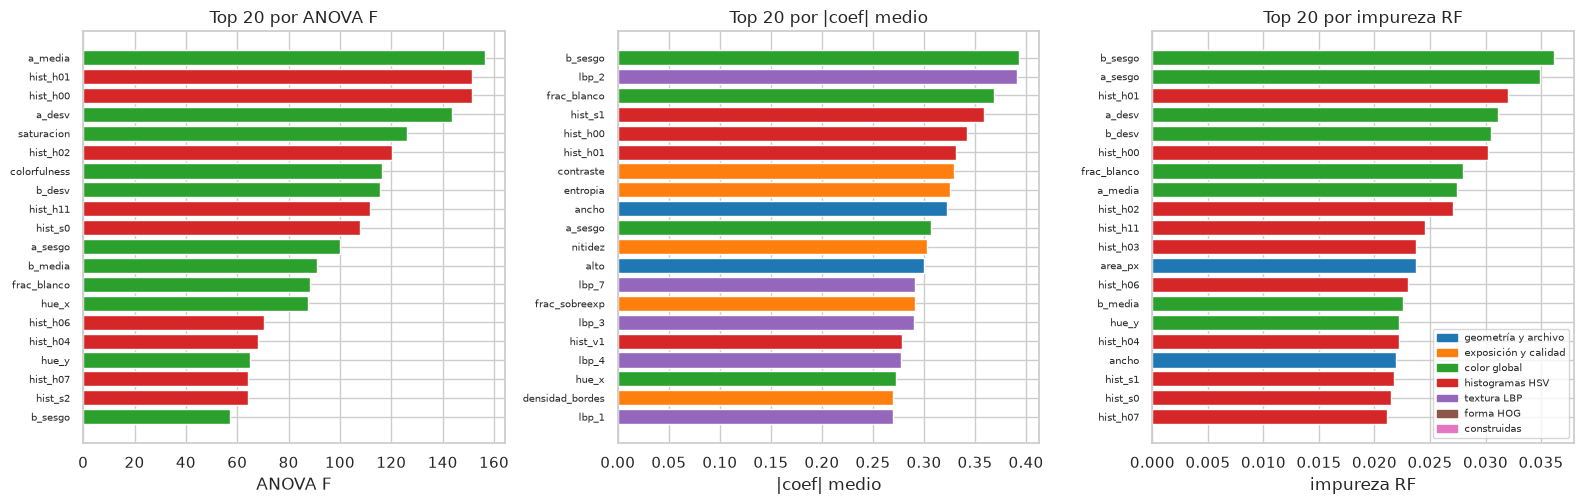

In [11]:
nombres_prep = base[:-2].get_feature_names_out() if 'seleccion' in base.named_steps \
               else base[:-1].get_feature_names_out()
sel = base.named_steps.get('seleccion')
mask = sel.get_support() if sel is not None else np.ones(len(nombres_prep), bool)
nombres_sel = np.asarray(nombres_prep)[mask]

imp = pd.DataFrame({'variable': nombres_sel,
                    'familia': [FAMILIA_DE[c] for c in nombres_sel],
                    'ANOVA F': (sel.scores_[mask] if sel is not None else f_classif(
                        base[:-1].transform(X_tr[cand]), y_tr)[0]),
                    '|coef| medio': np.abs(base.named_steps['clf'].coef_).mean(axis=0),
                    'impureza RF': ajustados['bosque aleatorio (300)'].named_steps['clf'].feature_importances_})
composicion = pd.DataFrame({'candidatas': pd.Series([FAMILIA_DE[c] for c in cand]).value_counts(),
                            f'seleccionadas (k={K})': imp['familia'].value_counts()}).fillna(0).astype(int)
display(composicion)
for col in ['ANOVA F', '|coef| medio', 'impureza RF']:
    print(f'Top 10 por {col}:', imp.nlargest(10, col)['variable'].tolist())

PALETA = dict(zip(FAMILIAS, sns.color_palette('tab10', len(FAMILIAS))))
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, col in zip(axes, ['ANOVA F', '|coef| medio', 'impureza RF']):
    t = imp.nlargest(20, col).iloc[::-1]
    ax.barh(t['variable'], t[col], color=[PALETA[f] for f in t['familia']])
    ax.set(title=f'Top 20 por {col}', xlabel=col); ax.tick_params(axis='y', labelsize=7)
axes[2].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETA.values()],
               labels=list(PALETA), fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()

,caída media de F1,desv.
familia,,
histogramas HSV,0.562,0.013
color global,0.424,0.010
textura LBP,0.272,0.015
exposición y calidad,0.184,0.013
geometría y archivo,0.137,0.011
construidas,0.014,0.003
forma HOG,0.000,0.000


,variables restantes,F1 prueba,cambio vs baseline
familia retirada,,,
geometría y archivo,611,0.867,-0.013
exposición y calidad,609,0.849,-0.032
color global,603,0.823,-0.058
histogramas HSV,596,0.775,-0.106
textura LBP,606,0.833,-0.047
forma HOG,62,0.881,0.000
construidas,609,0.875,-0.005


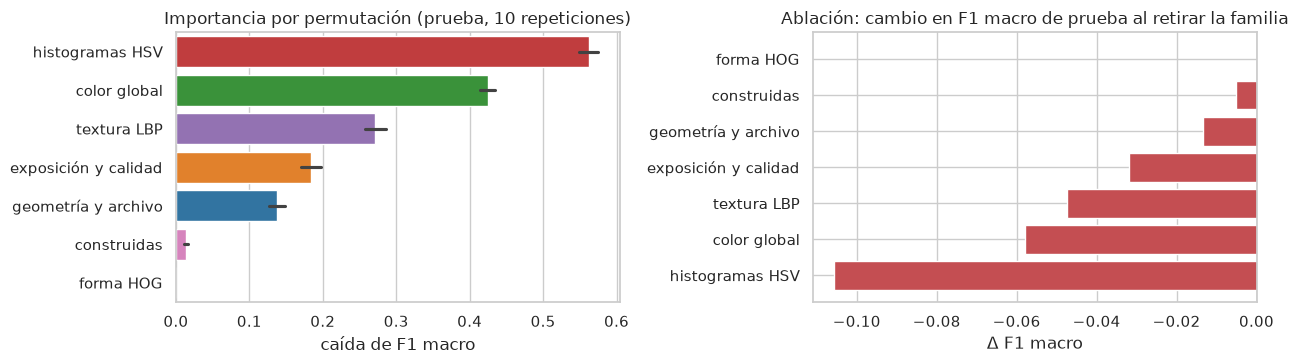

In [12]:
rng = np.random.default_rng(SEED)
Xte_c = X_te[cand]
f1_ref = f1_score(y_te, base.predict(Xte_c), average='macro')
perm = []
for fam, cols in FAMILIAS.items():
    cols = [c for c in cols if c in cand]
    if not cols:
        continue
    for _ in range(10):
        Xp = Xte_c.copy()
        Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]
        perm.append({'familia': fam, 'caída de F1 macro': f1_ref - f1_score(y_te, base.predict(Xp), average='macro')})
perm = pd.DataFrame(perm)
display(perm.groupby('familia')['caída de F1 macro'].agg(['mean', 'std']).sort_values('mean', ascending=False)
        .round(3).rename(columns={'mean': 'caída media de F1', 'std': 'desv.'}))

abla = []
for fam, cols in FAMILIAS.items():
    resto = [c for c in cand if c not in cols]
    m = pipe(logistica(), k=min(K, len(resto)), cols=resto).fit(X_tr[resto], y_tr)
    abla.append({'familia retirada': fam, 'variables restantes': len(resto),
                 'F1 prueba': f1_score(y_te, m.predict(X_te[resto]), average='macro')})
abla = pd.DataFrame(abla).set_index('familia retirada')
abla['cambio vs baseline'] = abla['F1 prueba'] - f1_ref
display(abla.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
orden_f = perm.groupby('familia')['caída de F1 macro'].mean().sort_values(ascending=False).index
sns.barplot(data=perm, y='familia', x='caída de F1 macro', order=orden_f, ax=axes[0],
            palette=PALETA, hue='familia', legend=False, errorbar='sd')
axes[0].set(title='Importancia por permutación (prueba, 10 repeticiones)', ylabel='')
a = abla['cambio vs baseline'].sort_values()
axes[1].barh(a.index, a.values, color=['#C44E52' if v < 0 else '#55A868' for v in a.values])
axes[1].axvline(0, c='k', lw=.8)
axes[1].set(title='Ablación: cambio en F1 macro de prueba al retirar la familia', xlabel='Δ F1 macro')
plt.tight_layout(); plt.show()

**Interpretación.** Los tres métodos coinciden en que **el color es la señal dominante**. ANOVA
selecciona las 13 variables de color global y 18 de los 20 histogramas HSV. La permutación lo confirma:
permutar los histogramas HSV hace caer el F1 macro en 0.56 y permutar el color global, en 0.42. Les
siguen la textura LBP (0.27) y la exposición y calidad (0.18). Las 10 variables con mayor F son el
componente rojo-verde de Lab (`a_media`, `a_desv`), los primeros intervalos de matiz (rojos y naranjas),
la saturación y el *colorfulness*: el color del empaque distingue marcas y presentaciones.

**La forma HOG no aporta en este modelo.** Ninguna de sus 554 variables candidatas entra en las 50
seleccionadas, y retirarla no cambia el F1 de prueba. Cada celda HOG separa poco por sí sola y ANOVA
evalúa las variables una por una; un modelo que combine los gradientes (por ejemplo, una red
convolucional) podría aprovecharla. Las variables construidas tampoco aportan de forma independiente
(caída de 0.014), porque repiten información de las originales.

**Señal a vigilar.** La familia de geometría y archivo (tamaño y peso del recorte) tiene una importancia
por permutación de 0.14, pero retirarla solo cuesta 0.013 de F1. Es decir, el modelo la usa pero puede
reemplazarla con otras variables. Como las dos campañas de captura difieren en dispositivo y recorte,
parte de esta señal puede deberse a cómo se tomó la foto y no al producto. Se recomienda no depender de
ella en los modelos siguientes hasta tener capturas de varias sesiones por producto.

La ablación confirma el orden: retirar los histogramas HSV es lo que más cuesta (−0.106), seguido del
color global (−0.058), la textura LBP (−0.047) y la exposición (−0.032).

## 7. ¿Sub o sobreajuste?

Se comparan las mismas métricas en tres conjuntos: entrenamiento (datos que el modelo ya vio),
validación cruzada (bloques temporales no vistos dentro de entrenamiento) y prueba (el último 30 % de
cada clase). Una brecha grande entre entrenamiento y validación indica sobreajuste; valores bajos en
ambos indican subajuste. Se complementa con dos curvas:

- **Curva de aprendizaje:** F1 macro de entrenamiento y validación al aumentar la cantidad de datos.
- **Curva de validación:** F1 macro en función de la regularización `C` de la regresión logística
  (valores pequeños regularizan más).

In [13]:
filas = []
for nom in ['regresión logística (baseline)', 'bosque aleatorio (300)']:
    m = ajustados[nom]
    cvm = evaluar_cv(pipe(MODELOS[nom], k=K)).drop(columns='seg ajuste').mean()
    for conj, vals in [('entrenamiento', metricas(m, X_tr[cand], y_tr)), ('validación cruzada', cvm.to_dict()),
                       ('prueba', metricas(m, X_te[cand], y_te))]:
        filas.append({'modelo': nom, 'conjunto': conj, **vals})
ajuste = pd.DataFrame(filas).set_index(['modelo', 'conjunto'])
display(ajuste.round(3))

F1 macro  exactitud  \
modelo                         conjunto                                  
regresión logística (baseline) entrenamiento          0.996      0.997   
                               validación cruzada     0.849      0.866   
                               prueba                 0.881      0.895   
bosque aleatorio (300)         entrenamiento          1.000      1.000   
                               validación cruzada     0.867      0.878   
                               prueba                 0.901      0.912   

                                                   exactitud balanceada  \
modelo                         conjunto                                   
regresión logística (baseline) entrenamiento                      0.996   
                               validación cruzada                 0.862   
                               prueba                             0.895   
bosque aleatorio (300)         entrenamiento                      1.000   
                               validación cruzada                 0.880   
                               prueba                             0.914   

                                                   top-3  log-loss  
modelo                         conjunto                             
regresión logística (baseline) entrenamiento       1.000     0.207  
                               validación cruzada  0.943     0.735  
                               prueba              0.951     0.629  
bosque aleatorio (300)         entrenamiento       1.000     0.191  
                               validación cruzada  0.950     1.190  
                               prueba              0.966     0.992

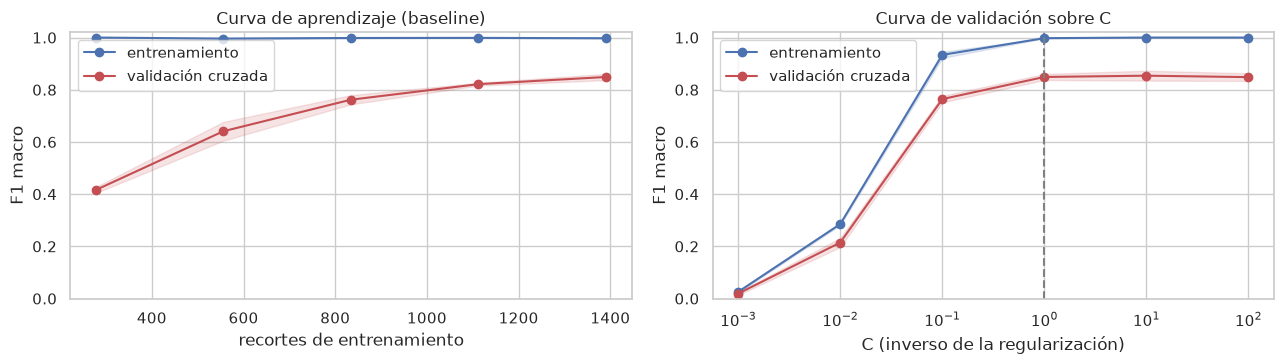

Curva de aprendizaje, F1 validación por tamaño: {278: np.float64(0.416), 556: np.float64(0.641), 834: np.float64(0.762), 1112: np.float64(0.821), 1391: np.float64(0.849)}
Curva de validación, F1 validación por C: {0.001: np.float64(0.019), 0.01: np.float64(0.215), 0.1: np.float64(0.764), 1: np.float64(0.849), 10: np.float64(0.854), 100: np.float64(0.848)}


In [14]:
tam, f1_tr_lc, f1_va_lc = learning_curve(
    pipe(logistica(), k=K), X_tr[cand], y_tr, groups=g_tr, cv=CV, scoring='f1_macro',
    train_sizes=np.linspace(0.2, 1.0, 5), shuffle=True, random_state=SEED, n_jobs=3)
RANGO_C = [0.001, 0.01, 0.1, 1, 10, 100]
f1_tr_vc, f1_va_vc = validation_curve(
    pipe(logistica(), k=K), X_tr[cand], y_tr, groups=g_tr, cv=CV, scoring='f1_macro',
    param_name='clf__C', param_range=RANGO_C, n_jobs=3)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, xs, tr, va, titulo, xl in [
        (axes[0], tam, f1_tr_lc, f1_va_lc, 'Curva de aprendizaje (baseline)', 'recortes de entrenamiento'),
        (axes[1], RANGO_C, f1_tr_vc, f1_va_vc, 'Curva de validación sobre C', 'C (inverso de la regularización)')]:
    for vals, et, c in [(tr, 'entrenamiento', '#4C72B0'), (va, 'validación cruzada', '#C44E52')]:
        ax.plot(xs, vals.mean(axis=1), marker='o', color=c, label=et)
        ax.fill_between(xs, vals.mean(axis=1) - vals.std(axis=1), vals.mean(axis=1) + vals.std(axis=1),
                        color=c, alpha=.15)
    ax.set(title=titulo, xlabel=xl, ylabel='F1 macro', ylim=(0, 1.02)); ax.legend()
axes[1].set_xscale('log'); axes[1].axvline(1.0, ls='--', c='gray')
plt.tight_layout(); plt.show()
print('Curva de aprendizaje, F1 validación por tamaño:',
      dict(zip(tam.tolist(), np.round(f1_va_lc.mean(axis=1), 3))))
print('Curva de validación, F1 validación por C:', dict(zip(RANGO_C, np.round(f1_va_vc.mean(axis=1), 3))))

**Interpretación.** El baseline muestra **sobreajuste moderado**: el F1 macro es de 0.996 en
entrenamiento, 0.849 en validación cruzada y 0.881 en prueba, una brecha de unos 0.15 puntos entre
entrenamiento y datos no vistos. El log-loss también sube, de 0.21 en entrenamiento a 0.74 en
validación. No hay subajuste, porque el desempeño fuera de entrenamiento es alto y está muy por encima
del azar. El bosque aleatorio memoriza por completo (F1 de 1.000 en entrenamiento), como es habitual en
los ensambles de árboles profundos, aunque generaliza ligeramente mejor.

Las curvas dan el diagnóstico:

- **Curva de aprendizaje.** El F1 de validación sube sin estabilizarse (0.42, 0.64, 0.76, 0.82, 0.85
  al pasar de 278 a 1 391 recortes) mientras el de entrenamiento se mantiene cerca de 1. Es el patrón
  de **alta varianza**: el modelo mejoraría con más imágenes por clase, que es la recomendación
  principal para Bnext.
- **Curva de validación.** Con regularización fuerte (C ≤ 0.01) el modelo subajusta (F1 de 0.02 a 0.22).
  El desempeño se estabiliza entre C = 1 y C = 10 (0.849 y 0.854) y no mejora con C = 100. El valor por
  defecto C = 1 ya está en la zona estable; su ajuste fino corresponde a la optimización de
  hiperparámetros del siguiente módulo.

Que la prueba (0.881) quede por encima de la validación cruzada (0.849) es consistente con el diseño: en
la validación cruzada cada modelo entrena con dos tercios del conjunto de entrenamiento, mientras que el
modelo final entrena con todo.

## 8. Métrica adecuada para el problema

El modelo alimenta la decisión de estado por posición del anaquel: si reconoce el producto
equivocado, una posición correcta se reporta como “mal ubicada” (alerta falsa que cuesta tiempo de
personal) o un producto fuera de lugar pasa como correcto (incumplimiento no detectado). El costo de
equivocarse es similar para cualquier producto, y en un planograma real cada producto suele ocupar
pocas posiciones, así que un error en un producto poco frecuente pesa igual que uno en un producto
muy frecuente. Por eso:

- **Métrica principal: F1 macro.** Promedia el F1 de cada clase con el mismo peso; combina la
  precisión (evitar alertas falsas) y la exhaustividad (no dejar pasar productos) y no se deja
  dominar por las clases con más imágenes. La exactitud global, en cambio, favorecería a las clases
  grandes en un conjunto con desbalance.
- **Métricas complementarias:** exactitud balanceada (exhaustividad media por clase), la proporción
  de clases con exhaustividad baja y la **exactitud top-3**, que mide si el producto correcto está
  entre las tres primeras opciones; esta última es útil si la operación incluye una revisión humana
  asistida.
- **Log-loss** solo como diagnóstico de la calidad de las probabilidades.

,clases,F1_macro,precisión,exhaustividad,clases_exh_bajo_0_5
origen,,,,,
agrupamiento,206.0,0.866,0.887,0.882,17.0
código,35.0,0.964,0.971,0.967,0.0
total,241.0,0.881,0.899,0.895,17.0


Exactitud top-3 en prueba: 0.951


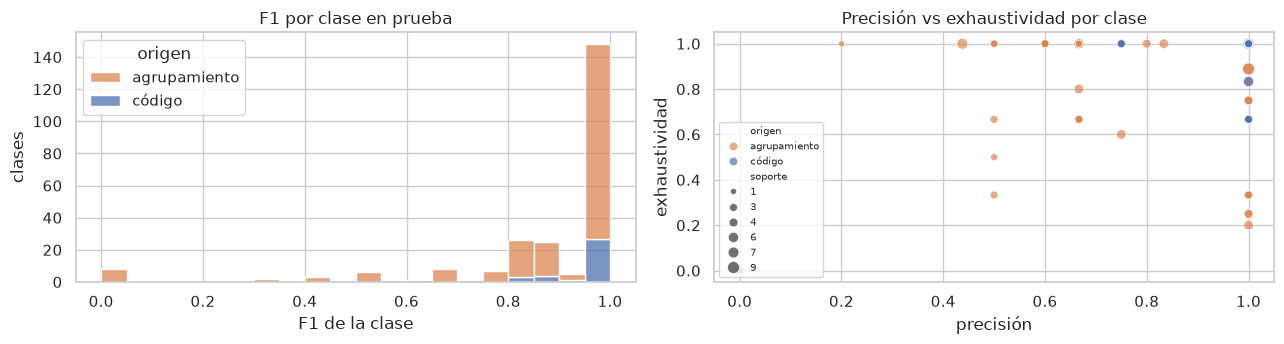

In [15]:
pred_te = base.predict(X_te[cand])
p, r, f, n = precision_recall_fscore_support(y_te, pred_te, labels=ETIQUETAS, zero_division=0)
por_clase_te = pd.DataFrame({'clase': le.classes_, 'origen': ORIGEN_CLASE, 'precisión': p,
                             'exhaustividad': r, 'F1': f, 'soporte': n})
res_origen = por_clase_te.groupby('origen').agg(clases=('clase', 'size'), F1_macro=('F1', 'mean'),
                                               precisión=('precisión', 'mean'),
                                               exhaustividad=('exhaustividad', 'mean'),
                                               clases_exh_bajo_0_5=('exhaustividad', lambda s: int((s < 0.5).sum())))
res_origen.loc['total'] = [len(por_clase_te), por_clase_te['F1'].mean(), por_clase_te['precisión'].mean(),
                           por_clase_te['exhaustividad'].mean(), int((por_clase_te['exhaustividad'] < 0.5).sum())]
display(res_origen.round(3))
print(f"Exactitud top-3 en prueba: {top_k_accuracy_score(y_te, probas(base, X_te[cand]), k=3, labels=ETIQUETAS):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
sns.histplot(data=por_clase_te, x='F1', hue='origen', multiple='stack', bins=20, ax=axes[0],
             palette={'código': '#4C72B0', 'agrupamiento': '#DD8452'})
axes[0].set(title='F1 por clase en prueba', xlabel='F1 de la clase', ylabel='clases')
sns.scatterplot(data=por_clase_te, x='precisión', y='exhaustividad', hue='origen', size='soporte',
                ax=axes[1], palette={'código': '#4C72B0', 'agrupamiento': '#DD8452'}, alpha=.7)
axes[1].set(title='Precisión vs exhaustividad por clase', xlim=(-.05, 1.05), ylim=(-.05, 1.05))
axes[1].legend(fontsize=7, loc='lower left'); plt.tight_layout(); plt.show()

In [16]:
cm = confusion_matrix(y_te, pred_te, labels=ETIQUETAS)
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(np.argsort(cm, axis=None)[::-1][:10], cm.shape)
confusiones = pd.DataFrame({'clase real': le.classes_[i], 'predicha como': le.classes_[j],
                            'recortes': cm[i, j]}).query('recortes > 0')
print('Pares de clases más confundidos en prueba:')
display(confusiones)
print('Clases con menor F1 en prueba:')
display(por_clase_te.nsmallest(10, 'F1').round(3).set_index('clase'))

Pares de clases más confundidos en prueba:


,clase real,predicha como,recortes
0,GRP_020,GRP_202,6
1,GRP_078,GRP_043,4
2,GRP_021,GRP_202,3
3,GRP_109,GRP_106,3
4,GRP_120,GRP_036,2
5,GRP_039,GRP_041,2
6,GRP_199,GRP_198,2
7,GRP_098,GRP_078,2
8,GRP_114,GRP_113,2
9,GRP_117,GRP_052,2


Clases con menor F1 en prueba:


,origen,precisión,exhaustividad,F1,soporte
clase,,,,,
GRP_020,agrupamiento,0.0,0.0,0.000,6
GRP_039,agrupamiento,0.0,0.0,0.000,2
GRP_078,agrupamiento,0.0,0.0,0.000,4
GRP_079,agrupamiento,0.0,0.0,0.000,3
GRP_090,agrupamiento,0.0,0.0,0.000,3
GRP_109,agrupamiento,0.0,0.0,0.000,3
GRP_111,agrupamiento,0.0,0.0,0.000,1
GRP_114,agrupamiento,0.0,0.0,0.000,3
GRP_021,agrupamiento,1.0,0.2,0.333,5


**Interpretación.** El F1 macro de prueba es **0.881**, con precisión media de 0.899 y exhaustividad
media de 0.895. El producto correcto está entre las tres primeras opciones en el **95.1 %** de los
recortes (top-3), así que una revisión asistida que muestre tres alternativas recuperaría casi todos los
errores.

El desglose por tipo de carpeta es el resultado más informativo:

- **Carpetas con código:** F1 macro de 0.964, y ningún producto con exhaustividad menor que 0.5. Es
  coherente con el Avance 2 (0.976 con 35 clases), aun compitiendo ahora contra 241 clases.
- **Carpetas de agrupamiento:** F1 macro de 0.866, y 17 de las 206 clases con exhaustividad menor que
  0.5. Las ocho clases con F1 = 0 y los pares más confundidos son todos de agrupamiento.

Esto es compatible con dos explicaciones que hay que distinguir con Bnext. La primera es que algunos
agrupamientos sean el mismo producto, o variantes muy parecidas, separados en dos carpetas: los pares
más confundidos tienen números consecutivos (por ejemplo, `GRP_198`/`GRP_199` y `GRP_113`/`GRP_114`), lo
que sugiere un origen común. La segunda es que sean productos distintos pero visualmente casi
idénticos. En el primer caso el error está en la etiqueta y no en el modelo. **Validar la
correspondencia de los agrupamientos con productos reales es la acción con mayor impacto en la
métrica**, antes que cambiar de algoritmo.

Por todo lo anterior, el F1 macro es la métrica adecuada: trata por igual a cada producto (un error en un
producto poco frecuente cuesta lo mismo en tienda) y deja ver estos problemas por clase, que la
exactitud global (0.895) ocultaría.

## 9. Desempeño mínimo

**Estado actual.** Bnext no ha proporcionado una medición histórica del desempeño del proceso actual
(revisión manual del anaquel), así que no existe un valor histórico contra el cual comparar. El
desempeño mínimo se establece con dos referencias:

1. **Piso estadístico:** el mejor clasificador de azar de la sección 4. El baseline debe superarlo
   con un margen que no se explique por la variación del conjunto de prueba; se verifica con un
   intervalo de confianza del 95 % por *bootstrap* (1 000 remuestreos de prueba).
2. **Piso de negocio:** el Avance 0 propuso como criterio de éxito una exactitud ≥ 0.85 en el estado
   asignado a cada posición (correcto, faltante, mal ubicado). Como ese estado depende de reconocer
   el producto, se adopta **F1 macro ≥ 0.85** como desempeño mínimo del reconocimiento. Es una meta
   propuesta por el equipo, pendiente de validar con el líder técnico de Bnext.

,F1 macro prueba,IC95 inferior,IC95 superior,supera piso de azar,cumple meta 0.85 (puntual),cumple meta 0.85 (IC95 inferior)
modelo,,,,,,
baseline,0.881,0.842,0.887,sí,sí,no
azar (uniforme),0.006,0.002,0.010,-,no,no
"baseline, clases de código",0.964,NaN,NaN,-,sí,-
"baseline, clases de agrupamiento",0.866,NaN,NaN,-,sí,-


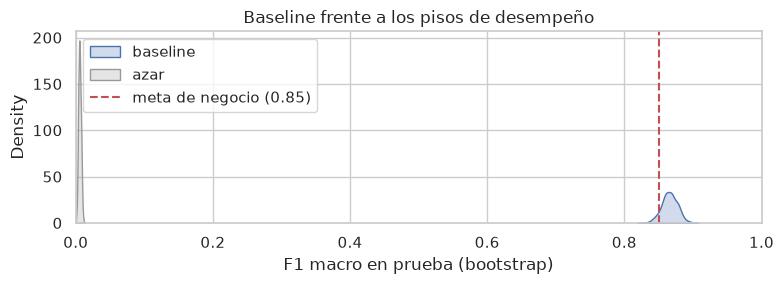

In [17]:
mejor_azar = azar['F1 macro prueba'].idxmax()
pred_azar = clone(DUMMIES[mejor_azar]).fit(X_tr[cand], y_tr).predict(X_te[cand])
rng = np.random.default_rng(SEED)
boot = {'baseline': [], 'azar': []}
for _ in range(1000):
    idx = rng.integers(0, len(y_te), len(y_te))
    boot['baseline'].append(f1_score(y_te[idx], pred_te[idx], average='macro'))
    boot['azar'].append(f1_score(y_te[idx], pred_azar[idx], average='macro'))
META = 0.85
filas = []
for nom, vals, punto in [('baseline', boot['baseline'], f1_ref),
                         (f'azar ({mejor_azar})', boot['azar'], f1_score(y_te, pred_azar, average='macro'))]:
    lo, hi = np.percentile(vals, [2.5, 97.5])
    filas.append({'modelo': nom, 'F1 macro prueba': punto, 'IC95 inferior': lo, 'IC95 superior': hi})
for org in ['código', 'agrupamiento']:
    filas.append({'modelo': f'baseline, clases de {org}',
                  'F1 macro prueba': por_clase_te.loc[por_clase_te['origen'] == org, 'F1'].mean()})
minimo = pd.DataFrame(filas).set_index('modelo')
techo_azar = minimo.loc[f'azar ({mejor_azar})', 'IC95 superior']
minimo['supera piso de azar'] = np.where(minimo['IC95 inferior'].isna(), '-',
                                         np.where(minimo['IC95 inferior'] > techo_azar, 'sí', 'no'))
minimo.loc[f'azar ({mejor_azar})', 'supera piso de azar'] = '-'
minimo['cumple meta 0.85 (puntual)'] = np.where(minimo['F1 macro prueba'] >= META, 'sí', 'no')
minimo['cumple meta 0.85 (IC95 inferior)'] = np.where(minimo['IC95 inferior'].isna(), '-',
                                                      np.where(minimo['IC95 inferior'] >= META, 'sí', 'no'))
display(minimo.round(3))

fig, ax = plt.subplots(figsize=(8, 3))
for nom, c in [('baseline', '#4C72B0'), ('azar', '#999999')]:
    sns.kdeplot(boot[nom], ax=ax, fill=True, color=c, label=nom, warn_singular=False)
ax.axvline(META, color='#C44E52', ls='--', label=f'meta de negocio ({META})')
ax.set(xlim=(0, 1), xlabel='F1 macro en prueba (bootstrap)', title='Baseline frente a los pisos de desempeño')
ax.legend(); plt.tight_layout(); plt.show()

**Interpretación.** El baseline obtiene un F1 macro de **0.881**, con un intervalo bootstrap del
95 % entre 0.842 y 0.887. El mejor clasificador de azar no pasa de 0.010. Supera el **piso
estadístico** con un margen enorme: los datos sí contienen información suficiente para reconocer el
producto, y el problema es viable con métodos simples.

Frente al **piso de negocio** (F1 macro ≥ 0.85), el baseline cumple por su valor puntual, pero el
extremo inferior del intervalo (0.842) queda ligeramente por debajo. El intervalo es asimétrico porque,
con pocas imágenes de prueba por clase, el remuestreo deja fuera algunas clases y tiende a subestimar el
F1 macro. Aun así, la conclusión prudente es que el baseline **está en el límite de la meta**, no
holgadamente por encima. Por tipo de carpeta, las clases con código (0.964) cumplen con amplitud y las de
agrupamiento (0.866) apenas la rebasan.

**El desempeño mínimo que deberá superar cualquier modelo de los siguientes avances es F1 macro 0.881
en esta misma partición de prueba**, con top-3 de 0.951. Un modelo nuevo se considerará mejor solo si
supera ese valor fuera del intervalo de variación observado.

## 10. Persistencia

El baseline ajustado y la tabla de características se guardan en `PLANOGRAMA_OUT_DIR`, dentro de la
infraestructura de Bnext, para que los avances siguientes se comparen contra exactamente el mismo
modelo y la misma partición. Ambos archivos quedan fuera del repositorio (`.gitignore`).

In [18]:
joblib.dump({'pipeline': base, 'columnas': cand, 'k': K, 'clases': list(le.classes_),
             'metricas_prueba': metricas(base, X_te[cand], y_te)}, OUT_DIR / 'avance3_baseline.joblib')
df.drop(columns=['orden']).assign(particion=np.where(es_train, 'train', 'test')) \
  .to_csv(OUT_DIR / 'avance3_caracteristicas_recortes.csv', index=False)
print('Archivos generados:', sorted(p.name for p in OUT_DIR.glob('avance3_*')))

Archivos generados: ['avance3_baseline.joblib', 'avance3_caracteristicas_recortes.csv']


## Conclusiones (CRISP-ML(Q): ingeniería del modelo)

1. **Algoritmo.** El baseline es una regresión logística multinomial sobre 50 características
   seleccionadas con ANOVA, después de las transformaciones de potencia, la estandarización y los filtros
   de varianza y redundancia del Avance 2. Se eligió por el tipo de datos (tabulares, numéricos y
   estandarizados), por la poca cantidad de imágenes por clase, por su interpretabilidad y por sus
   probabilidades calibradas. Entrena en unos 13 segundos en CPU.
2. **Características importantes.** El color (histogramas HSV, Lab, saturación) explica la mayor parte
   del desempeño, seguido de la textura LBP y la exposición. La forma HOG no aporta en un modelo lineal
   con selección univariada. La geometría y el peso del archivo deben vigilarse como posible artefacto de
   captura.
3. **Ajuste.** Hay sobreajuste moderado: F1 de 0.996 en entrenamiento contra 0.849 en validación. La
   curva de aprendizaje sigue subiendo, así que más imágenes por clase es la palanca principal. No hay
   subajuste con la regularización por defecto.
4. **Métrica.** F1 macro como métrica principal, con top-3 y desglose por clase. El desglose muestra que
   los errores se concentran en las carpetas de agrupamiento.
5. **Desempeño mínimo.** El baseline (F1 macro 0.881, top-3 0.951) supera al azar por más de dos órdenes
   de magnitud y alcanza en el límite la meta de 0.85 propuesta en el Avance 0. Ese valor queda fijado
   como el piso para los modelos siguientes.

**Riesgos y siguientes pasos.**

- Validar con Bnext a qué producto corresponde cada carpeta de agrupamiento y si hay agrupamientos que
  deban fusionarse. Es la acción con mayor impacto esperado en la métrica.
- Solicitar capturas de más de una sesión por producto. Con una sola sesión, las métricas miden
  separabilidad y no generalización.
- Mientras no existan anotaciones de escena, el reconocimiento de recortes es el componente que se
  puede medir. La detección en el anaquel completo requiere anotar un subconjunto de escenas.
- En el Avance 4 se compararán contra este baseline el bosque aleatorio y modelos basados en
  representaciones aprendidas, con la optimización de hiperparámetros del siguiente módulo.

## Referencias

Dalal, N., y Triggs, B. (2005). Histograms of oriented gradients for human detection. En *2005 IEEE
Computer Society Conference on Computer Vision and Pattern Recognition* (Vol. 1, pp. 886–893). IEEE.
https://doi.org/10.1109/CVPR.2005.177

Efron, B., y Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.

Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3a ed.).
O'Reilly Media.

Ojala, T., Pietikäinen, M., y Mäenpää, T. (2002). Multiresolution gray-scale and rotation invariant
texture classification with local binary patterns. *IEEE Transactions on Pattern Analysis and Machine
Intelligence, 24*(7), 971–987. https://doi.org/10.1109/TPAMI.2002.1017623

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M.,
Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M.,
Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine
Learning Research, 12*, 2825–2830.

Sokolova, M., y Lapalme, G. (2009). A systematic analysis of performance measures for classification
tasks. *Information Processing & Management, 45*(4), 427–437. https://doi.org/10.1016/j.ipm.2009.03.002

Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., y Plöd, M. (2023). *CRISP-ML(Q). The ML lifecycle
process*. MLOps. INNOQ. https://ml-ops.org/content/crisp-ml